In [1]:
# Experiment 01 — Bernstein–Vazirani Algorithm

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

In [3]:
# Define the hidden binary string
secret = "101"

# Count the input qubits
n = len(secret)

print("Hidden String:", secret)
print("Number of Input Qubits:", n)

Hidden String: 101
Number of Input Qubits: 3


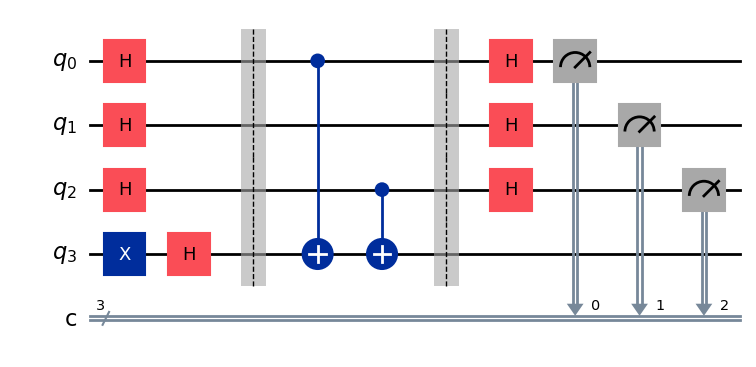

In [5]:
# Create input qubits and one output qubit
qc = QuantumCircuit(n + 1, n)

# Prepare the output qubit in |1>
qc.x(n)

# Apply Hadamard gates
qc.h(range(n + 1))

qc.barrier()

# Apply the oracle for the hidden string
for i, bit in enumerate(reversed(secret)):
    if bit == "1":
        qc.cx(i, n)

qc.barrier()

# Apply Hadamard gates to the input qubits
qc.h(range(n))

# Measure the input qubits
qc.measure(range(n), range(n))

# Display the circuit
display(qc.draw("mpl"))

In [6]:
# Create the simulator
simulator = AerSimulator()

# Run the circuit 1024 times
result = simulator.run(
    transpile(qc, simulator),
    shots=1024,
    seed_simulator=42
).result()

counts = result.get_counts()

print("Measurement Counts:", counts)

Measurement Counts: {'101': 1024}


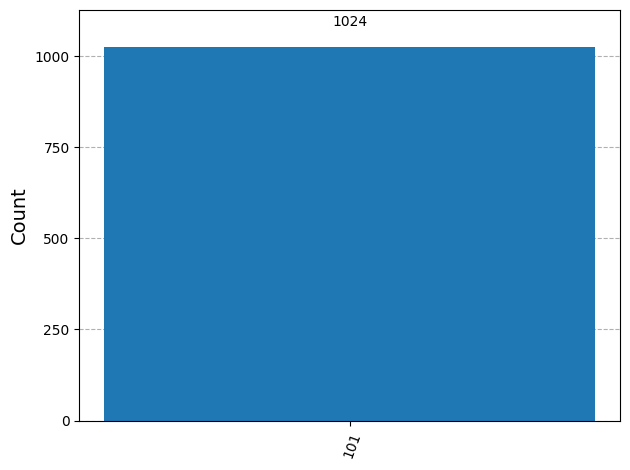

In [7]:
# Plot the measurement results
display(plot_histogram(counts))

In [8]:
# Find the most frequently measured result
measured_string = max(counts, key=counts.get)

print("Original Hidden String:", secret)
print("Measured Hidden String:", measured_string)

# Check whether the result is correct
print("Result Matches:", measured_string == secret)

Original Hidden String: 101
Measured Hidden String: 101
Result Matches: True
